# 03 · Job titles: what really happened

**What this notebook does, in plain words**

This is the "reality" half of the Loan Officer Audit. Before asking an AI anything, we measure how borrowers with each job title **actually** repaid, compared with what LendingClub's grade predicted for them. These numbers are the answer key the AI will be checked against later.

It follows `PREREGISTRATION.md`, which fixed the 12 titles and the method before any AI results were collected.

1. For every loan, work out what its grade predicted: the default rate of loans with the same sub-grade issued in the same year.
2. For each title, the **real gap** = actual default rate minus what the grade predicted. Negative means safer than the grade thought; positive means riskier.
3. Check that each gap keeps its sign between loans issued before 2015 and loans issued in 2015 (go/no-go: at least 8 of 12).

**About dates:** job titles only appear in this data from late 2013 (see the note below). So although the file covers 2007–2015, every gap here really comes from loans issued **late 2013 to 2015**.
4. Audit our own model from notebook 02, which never sees job titles: does it miss title-related risk?
5. Save one chart and one table.

## Load the clean loans

We use `job_title` exactly as notebook 01 cleaned it (lowercase, trimmed), with no merging of similar titles. "nurse" and "registered nurse" really do behave differently in this data. Loans with no title get the label `(blank)`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_parquet("data/loans_clean.parquet")
df["title"] = df["job_title"].fillna("(blank)")

PREREGISTERED = [
    "software engineer", "police officer", "executive assistant", "attorney", "teacher",
    "registered nurse", "mechanic", "president", "general manager", "owner", "truck driver", "server",
]
EXTRAS = ["(blank)", "employee"]
CONDITIONS = PREREGISTERED + EXTRAS

print(f"{len(df):,} loans, issued {df['year'].min()}-{df['year'].max()}")
df[df["title"].isin(CONDITIONS)]["title"].value_counts().reindex(CONDITIONS).rename("loans").to_frame()

618,584 loans, issued 2007-2015


,loans
title,
software engineer,1102
police officer,1597
executive assistant,1246
attorney,1700
teacher,11538
registered nurse,5523
mechanic,1348
president,2381
general manager,2970


## A data note we caught: before late 2013, "job title" was the employer

LendingClub's `emp_title` field didn't always mean the same thing. **Before late 2013 it held the employer's name** (for example "us army", "bank of america", "walmart"). After that, it held the borrower's **job title** ("teacher", "manager", "registered nurse").

The table below shows this directly: the most common values in each year, and how many loans carry one of our 12 job titles. Our titles are almost absent until the fourth quarter of 2013.

**What it means for this project:**

- **The gaps are still valid.** Every real gap here is computed only from loans that really carry these job titles, so they reflect job titles, not employers.
- **The time period is narrower than it sounds.** The data runs from 2007 to 2015, but the job-title gaps come from loans issued **late 2013 to 2015**. Columns named `gap_2007_2014` (kept under that name so later notebooks still work) really cover loans issued **before 2015**, which in practice means June 2012 to December 2014, almost all from Q4 2013 onward.
- **Notebooks 05 and 08** describe their periods with this correction.

In [2]:
by_year = df.groupby("year").apply(lambda g: pd.Series({
    "loans": len(g),
    "with one of the 12 titles": int(g["title"].isin(PREREGISTERED).sum()),
    "top 4 values of emp_title": ", ".join(g.loc[g["title"] != "(blank)", "title"].value_counts().head(4).index),
}))
display(by_year)
q = df[df["title"].isin(PREREGISTERED) & df["year"].between(2012, 2013)]
print("Loans with one of the 12 titles, 2012-2013 by quarter:",
      {str(k): int(v) for k, v in q.groupby(q["issue_date"].dt.to_period("Q")).size().items()})

,loans,with one of the 12 titles,top 4 values of emp_title
year,,,
2007,251,0,"affinity marketing group, bank of america corp..."
2008,1562,0,"self, self-employed, self employed, retired"
2009,4716,0,"self employed, retired, self, us air force"
2010,8466,0,"us army, bank of america, walmart, at&t"
2011,14101,0,"us army, bank of america, walmart, at&t"
2012,43470,2,"us army, bank of america, walmart, kaiser perm..."
2013,100422,2070,"teacher, manager, registered nurse, rn"
2014,162570,13383,"teacher, manager, registered nurse, owner"
2015,283026,24551,"teacher, manager, owner, registered nurse"


Loans with one of the 12 titles, 2012-2013 by quarter: {'2012Q2': 2, '2013Q2': 1, '2013Q3': 2, '2013Q4': 2067}


## What did the grade predict for each loan?

A loan's **expected default** is the default rate of all *other* loans with the same sub-grade issued in the same year. Leaving the loan itself out (as the pre-registration says) means a loan's own outcome can't leak into its own prediction. With thousands of loans per group, this changes the numbers only in the third decimal place.

Using the same year matters: a B3 loan from 2010 and a B3 loan from 2015 had different real risk.

In [3]:
group = df.groupby(["year", "sub_grade"])["default"]
group_sum, group_size = group.transform("sum"), group.transform("size")
df["expected"] = (group_sum - df["default"]) / (group_size - 1)
df["gap"] = df["default"] - df["expected"]   # +1 or -1-ish per loan; averages become the title's gap

print("Loans dropped because they were alone in their group:", int(df["expected"].isna().sum()))
df = df.dropna(subset=["expected"])
print(f"Average gap over ALL loans: {df['gap'].mean() * 100:+.2f} points (should be about 0)")

Loans dropped because they were alone in their group: 9
Average gap over ALL loans: -0.00 points (should be about 0)


## The bootstrap: how sure are we about each gap?

A title's gap is an average over its loans. To see how much that average could wobble by chance, we **resample**: draw that title's loans at random with replacement (some picked twice, some not at all), recompute the average, and repeat 2,000 times. The middle 95% of those 2,000 averages is the **95% interval**. If the interval doesn't include zero, the gap is unlikely to be luck.

A fixed random seed means anyone rerunning this gets the same numbers.

In [4]:
RNG_SEED = 2015
N_RESAMPLES = 2_000

def gap_with_interval(values, seed=RNG_SEED):
    """Mean of `values` in percentage points, plus a 95% bootstrap interval."""
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = np.array([values[rng.integers(0, len(values), len(values))].mean() for _ in range(N_RESAMPLES)])
    low, high = np.percentile(means, [2.5, 97.5])
    return len(values), values.mean() * 100, low * 100, high * 100

## The real gaps (loans issued late 2013 to 2015)

For each of the 12 pre-registered titles plus `(blank)` and `employee`: how many loans, the real gap, and its 95% interval. All in percentage points.

In [5]:
rows = []
for title in CONDITIONS:
    loans, gap, low, high = gap_with_interval(df.loc[df["title"] == title, "gap"])
    rows.append({"condition": title, "preregistered": title in PREREGISTERED,
                 "loans": loans, "real_gap_pp": gap, "ci_low": low, "ci_high": high})
real = pd.DataFrame(rows).set_index("condition")
real.sort_values("real_gap_pp").round(1)

,preregistered,loans,real_gap_pp,ci_low,ci_high
condition,,,,,
software engineer,True,1102,-5.8,-7.2,-4.5
police officer,True,1597,-3.7,-5.0,-2.2
executive assistant,True,1246,-3.4,-5.0,-1.7
attorney,True,1700,-3.2,-4.4,-1.9
teacher,True,11538,-2.1,-2.7,-1.5
registered nurse,True,5523,-1.0,-1.8,-0.1
mechanic,True,1348,-0.2,-2.1,1.8
president,True,2381,0.2,-1.1,1.5
general manager,True,2970,2.5,1.2,3.8


## Sign stability: is each gap a lasting pattern or a one-off?

If teachers were safer than their grade before 2015 but riskier in 2015, the "real gap" would be too shaky to judge an AI against. So we compute each gap separately for the two periods and check whether its sign (safer or riskier) stays the same.

**Go/no-go (pre-registered): at least 8 of the 12 titles keep their sign.** Titles that flip are left out of the main AI comparison.

In [6]:
early = df[df["year"] <= 2014].groupby("title")["gap"].mean().mul(100)
late = df[df["year"] == 2015].groupby("title")["gap"].mean().mul(100)

real["gap_2007_2014"] = early.reindex(real.index)
real["gap_2015"] = late.reindex(real.index)
real["same_sign"] = np.sign(real["gap_2007_2014"]) == np.sign(real["gap_2015"])

kept = int(real.loc[PREREGISTERED, "same_sign"].sum())
flipped = list(real.loc[PREREGISTERED][~real.loc[PREREGISTERED, "same_sign"]].index)
print(f"{kept} of 12 pre-registered titles keep the same sign  ->  {'GO' if kept >= 8 else 'NO-GO'} (need at least 8)")
print("Titles that flip:", ", ".join(flipped) if flipped else "none")
real[["gap_2007_2014", "gap_2015", "same_sign"]].sort_values("gap_2007_2014").round(1)

10 of 12 pre-registered titles keep the same sign  ->  GO (need at least 8)
Titles that flip: mechanic, president


,gap_2007_2014,gap_2015,same_sign
condition,,,
software engineer,-7.3,-4.8,True
police officer,-4.9,-2.7,True
attorney,-3.8,-2.8,True
executive assistant,-3.7,-3.2,True
president,-2.1,1.4,False
teacher,-1.8,-2.4,True
registered nurse,-1.1,-0.9,True
mechanic,0.7,-0.8,False
general manager,1.6,3.0,True


## Auditing our own model

Our model from notebook 02 never saw job titles. Here we check, on the 2015 test loans, whether it **misses** risk linked to job title: for each title, the average of (actual default − the model's predicted risk).

One thing to keep in mind: the model under-predicts 2015 overall (2015 loans defaulted more than the 2007–2014 loans it learned from). So every title will tend to come out positive. The fair comparison is each title **against the all-loan average**, shown in the last column. A title well above that average is one where the model is missing something.

In [7]:
scored = pd.read_parquet("data/test_2015_scored.parquet")
scored["title"] = scored["job_title"].fillna("(blank)")
scored["model_gap"] = scored["default"] - scored["model_risk"]

overall_model_gap = scored["model_gap"].mean() * 100
print(f"All 2015 loans: actual minus model = {overall_model_gap:+.1f} points (the model's overall under-prediction)")

model_rows = []
for title in CONDITIONS:
    loans, gap, low, high = gap_with_interval(scored.loc[scored["title"] == title, "model_gap"])
    model_rows.append({"condition": title, "model_loans_2015": loans, "model_gap_pp": gap,
                       "model_ci_low": low, "model_ci_high": high})
model_audit = pd.DataFrame(model_rows).set_index("condition")
model_audit["model_gap_vs_all_loans_pp"] = model_audit["model_gap_pp"] - overall_model_gap

real = real.join(model_audit)
real.sort_values("real_gap_pp")[["real_gap_pp", "model_loans_2015", "model_gap_pp",
                                 "model_ci_low", "model_ci_high", "model_gap_vs_all_loans_pp"]].round(1)

All 2015 loans: actual minus model = +1.6 points (the model's overall under-prediction)


,real_gap_pp,model_loans_2015,model_gap_pp,model_ci_low,model_ci_high,model_gap_vs_all_loans_pp
condition,,,,,,
software engineer,-5.8,644,-2.1,-3.9,-0.2,-3.6
police officer,-3.7,905,-0.4,-2.2,1.8,-1.9
executive assistant,-3.4,754,-1.4,-3.7,0.8,-3.0
attorney,-3.2,1024,-1.9,-3.5,-0.3,-3.5
teacher,-2.1,6820,-1.0,-1.8,-0.3,-2.6
registered nurse,-1.0,3144,0.9,-0.3,2.1,-0.7
mechanic,-0.2,797,1.9,-0.6,4.4,0.3
president,0.2,1548,3.8,2.1,5.5,2.3
general manager,2.5,1799,4.6,2.9,6.3,3.1


## The chart: each title against what the grade predicted

One row per condition, sorted from safest to riskiest. The dot is the real gap and the line is its 95% interval. Left of zero means borrowers with that title defaulted **less** than their grade predicted. `(blank)` is labelled in gray because it wasn't among the 12 pre-registered titles.

`employee` is left off the chart: only 28 loans have that title, so its interval runs from about −4 to +30 points and would squash every other row. Its numbers are still in the table, with a note under the chart.

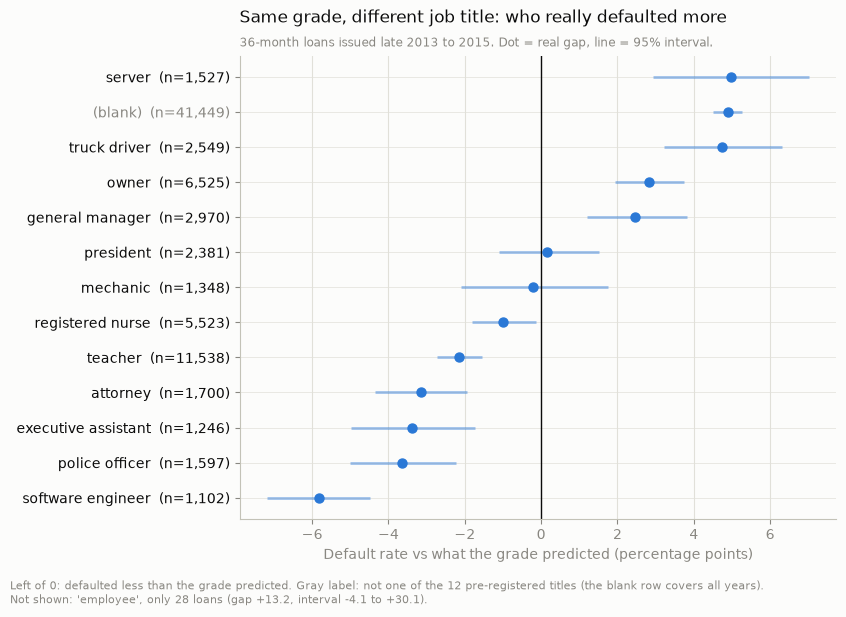

In [8]:
BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#898781", "#e1e0d9"
TOO_FEW_LOANS = 200   # rows with fewer loans than this are noted under the chart instead of plotted
plot = real[real["loans"] >= TOO_FEW_LOANS].sort_values("real_gap_pp")
left_out = real[real["loans"] < TOO_FEW_LOANS]
y = np.arange(len(plot))

fig, ax = plt.subplots(figsize=(8.5, 6.2), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.hlines(y, plot["ci_low"], plot["ci_high"], color=BLUE, linewidth=2, alpha=0.45)
ax.scatter(plot["real_gap_pp"], y, color=BLUE, s=42, zorder=3)
ax.axvline(0, color=INK, linewidth=1)

ax.set_yticks(y, [f"{t}  (n={n:,})" for t, n in zip(plot.index, plot["loans"])])
ax.set_xlabel("Default rate vs what the grade predicted (percentage points)", color=MUTED)
ax.set_title("Same grade, different job title: who really defaulted more", loc="left", color=INK, fontsize=12, pad=24)
ax.text(0, 1.02, "36-month loans issued late 2013 to 2015. Dot = real gap, line = 95% interval.",
        transform=ax.transAxes, color=MUTED, fontsize=8.5)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.grid(axis="y", color=GRID, linewidth=0.5)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["bottom", "left"]:
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors=MUTED)
# Colour the labels AFTER tick_params, which would otherwise turn them all gray
for label, is_prereg in zip(ax.get_yticklabels(), plot["preregistered"]):
    label.set_color(INK if is_prereg else MUTED)

notes = ["Left of 0: defaulted less than the grade predicted. Gray label: not one of the 12 pre-registered titles (the blank row covers all years)."]
for title, row in left_out.iterrows():
    notes.append(f"Not shown: '{title}', only {row['loans']:,} loans (gap {row['real_gap_pp']:+.1f}, "
                 f"interval {row['ci_low']:+.1f} to {row['ci_high']:+.1f}).")
plt.tight_layout(rect=(0, 0.06, 1, 1))
fig.text(0.01, 0.012, "\n".join(notes), color=MUTED, fontsize=8, ha="left", va="bottom")

Path("outputs").mkdir(exist_ok=True)
fig.savefig("outputs/real_gaps.png", dpi=200)
plt.show()

## Save the answer key

The table goes to `outputs/real_gaps.csv`. Notebook 04 (the AI loan officer) will load it and compare the AI's job-title effects against these real gaps.

In [9]:
COLUMNS = ["preregistered", "loans", "real_gap_pp", "ci_low", "ci_high",
           "gap_2007_2014", "gap_2015", "same_sign",
           "model_loans_2015", "model_gap_pp", "model_ci_low", "model_ci_high", "model_gap_vs_all_loans_pp"]
real.sort_values("real_gap_pp")[COLUMNS].round(2).to_csv("outputs/real_gaps.csv")
print("Saved outputs/real_gaps.csv and outputs/real_gaps.png")

Saved outputs/real_gaps.csv and outputs/real_gaps.png
